# Task 1: Customer Data EDA, Cleaning, Merge Validation and Product Recommendation

This notebook is the Data Lead deliverable. It loads the social-profile and transaction workbooks, documents data quality decisions, creates EDA outputs, validates an inner merge, and trains a Random Forest product recommendation model.

In [1]:
from pathlib import Path
import io, json
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR, REPORTS_DIR, MODELS_DIR = PROJECT_ROOT / "data", PROJECT_ROOT / "reports", PROJECT_ROOT / "models"
REPORTS_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")


## 1. Load and inspect the datasets

In [2]:
social_profiles = pd.read_excel(DATA_DIR / "customer_social_profiles.xlsx")
customer_transactions = pd.read_excel(DATA_DIR / "customer_transactions.xlsx")
print("Social profiles shape:", social_profiles.shape)
print("Transactions shape:", customer_transactions.shape)
social_profiles.info(); customer_transactions.info()
display(social_profiles.describe(include="all").transpose())
display(customer_transactions.describe(include="all").transpose())


Social profiles shape: (155, 5)
Transactions shape: (150, 6)
<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    str    
 1   social_media_platform    155 non-null    str    
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 9.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id_legacy  150 non-null    int64         
 1   transaction_id      150 non-null    int64         
 2   purchase_amount     150 non-null    int64         
 3   purchase_date       150 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_new,155,84,A155,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
social_media_platform,155,5,Twitter,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engagement_score,155.0,NaN,NaN,NaN,75.606452,14.568021,50.0,63.5,77.0,87.5,99.0
purchase_interest_score,155.0,NaN,NaN,NaN,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0
review_sentiment,155,3,Positive,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id_legacy,150.0,NaN,NaN,NaN,148.76,100.0,121.25,150.5,174.75,199.0,30.046425
transaction_id,150.0,NaN,NaN,NaN,1075.5,1001.0,1038.25,1075.5,1112.75,1150.0,43.445368
purchase_amount,150.0,NaN,NaN,NaN,280.78,51.0,179.0,274.0,388.5,495.0,121.329595
purchase_date,150,NaN,NaN,NaN,2024-03-15 12:00:00,2024-01-01 00:00:00,2024-02-07 06:00:00,2024-03-15 12:00:00,2024-04-21 18:00:00,2024-05-29 00:00:00,NaN
product_category,150,5,Sports,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_rating,140.0,NaN,NaN,NaN,2.985,1.0,1.95,3.0,4.0,5.0,1.20699


## 2. Variable types, missing values and duplicates

In [3]:
def variable_types(data, name):
    rows = []
    for column in data.columns:
        if pd.api.types.is_numeric_dtype(data[column]): kind = "numeric"
        elif "date" in column.lower() or "time" in column.lower(): kind = "date"
        else: kind = "categorical"
        rows.append({"dataset": name, "variable": column, "type": kind, "pandas_dtype": str(data[column].dtype)})
    return pd.DataFrame(rows)

raw_variable_types = pd.concat([variable_types(social_profiles, "social_profiles"), variable_types(customer_transactions, "customer_transactions")])
display(raw_variable_types)
display(pd.DataFrame({"social_profiles_missing": social_profiles.isna().sum(), "transactions_missing": customer_transactions.isna().sum()}).fillna(0).astype(int))
print("Duplicate social-profile rows:", social_profiles.duplicated().sum())
print("Duplicate transaction rows:", customer_transactions.duplicated().sum())
raw_variable_types.to_csv(REPORTS_DIR / "customer_variable_types_before_cleaning.csv", index=False)


,dataset,variable,type,pandas_dtype
0,social_profiles,customer_id_new,categorical,str
1,social_profiles,social_media_platform,categorical,str
2,social_profiles,engagement_score,numeric,int64
3,social_profiles,purchase_interest_score,numeric,float64
4,social_profiles,review_sentiment,date,str
0,customer_transactions,customer_id_legacy,numeric,int64
1,customer_transactions,transaction_id,numeric,int64
2,customer_transactions,purchase_amount,numeric,int64
3,customer_transactions,purchase_date,date,datetime64[us]
4,customer_transactions,product_category,categorical,str


,social_profiles_missing,transactions_missing
customer_id_legacy,0,0
customer_id_new,0,0
customer_rating,0,10
engagement_score,0,0
product_category,0,0
purchase_amount,0,0
purchase_date,0,0
purchase_interest_score,0,0
review_sentiment,0,0
social_media_platform,0,0


Duplicate social-profile rows: 5
Duplicate transaction rows: 0


## 3. Clean and merge

Exact duplicate rows are removed. Numeric missing values use the median, categorical missing values use the mode, and dates are converted to datetime. An inner join is justified because modeling rows need both transaction and social-profile information. The key normalizes `A178` and `178` to the same customer ID.

In [4]:
social_profiles = social_profiles.drop_duplicates().copy()
customer_transactions = customer_transactions.drop_duplicates().copy()
for data in (social_profiles, customer_transactions):
    for column in data.select_dtypes(include="number").columns:
        data[column] = data[column].fillna(data[column].median())
    for column in data.select_dtypes(include=["object", "string", "category"]).columns:
        if data[column].isna().any():
            mode = data[column].mode(dropna=True)
            data[column] = data[column].fillna(mode.iloc[0] if not mode.empty else "Unknown")
customer_transactions["purchase_date"] = pd.to_datetime(customer_transactions["purchase_date"], errors="coerce")

def normalize_customer_id(values):
    values = values.astype("string").str.strip()
    suffix = values.str.extract(r"(\d+)$")[0]
    return suffix.where(suffix.notna(), values)

social_profiles["join_customer_id"] = normalize_customer_id(social_profiles["customer_id_new"])
# Keep one profile per customer to prevent a many-to-many merge.
social_profiles = social_profiles.drop_duplicates(subset=["join_customer_id"], keep="first")
customer_transactions["join_customer_id"] = normalize_customer_id(customer_transactions["customer_id_legacy"])
rows_before_merge = len(customer_transactions)
clean_merged_customer_data = customer_transactions.merge(social_profiles, on="join_customer_id", how="inner", suffixes=("", "_profile")).drop(columns="join_customer_id")
post_merge_checks = {"rows_before_merge": rows_before_merge, "rows_after_merge": len(clean_merged_customer_data), "null_count_after_merge": int(clean_merged_customer_data.isna().sum().sum()), "duplicate_count_after_merge": int(clean_merged_customer_data.duplicated().sum())}
display(pd.DataFrame([post_merge_checks])); display(clean_merged_customer_data.head())
clean_merged_customer_data.to_csv(DATA_DIR / "clean_merged_customer_dataset.csv", index=False)


,rows_before_merge,rows_after_merge,null_count_after_merge,duplicate_count_after_merge
0,150,117,0,0


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,151,1001,408,2024-01-01,Sports,2.3,A151,TikTok,61,1.3,Neutral
1,192,1002,332,2024-01-02,Electronics,4.2,A192,Instagram,60,4.3,Positive
2,114,1003,442,2024-01-03,Electronics,2.1,A114,Facebook,87,4.8,Negative
3,160,1005,64,2024-01-05,Clothing,1.3,A160,TikTok,56,2.6,Positive
4,120,1006,395,2024-01-06,Groceries,1.1,A120,Facebook,83,1.4,Positive


## 4. EDA plots and interpretations

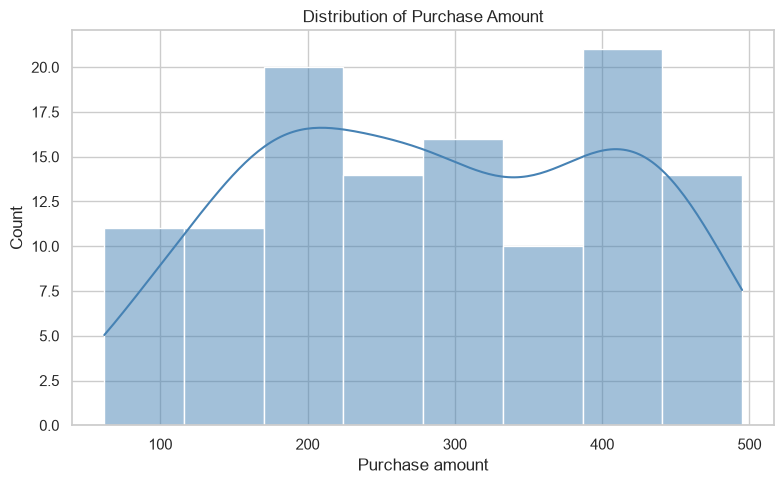

Interpretation: This distribution shows where purchase amounts are concentrated and whether they are skewed. Skew and extreme values matter because they can affect averages, scaling, and model behavior.


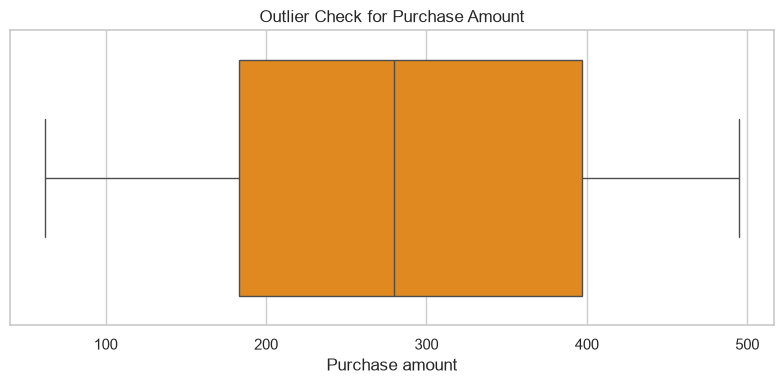

Interpretation: The boxplot highlights the median, interquartile range, and unusual purchases. Outliers should be investigated because they may disproportionately influence statistics and some algorithms.


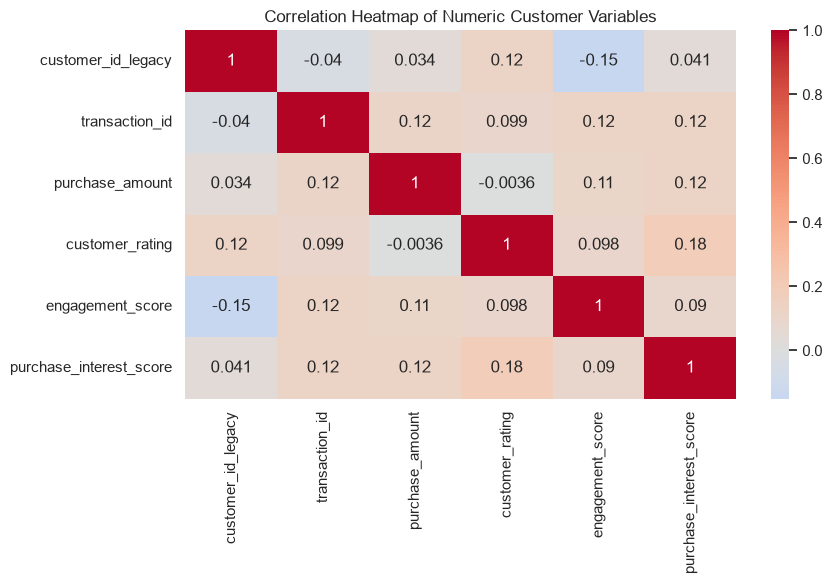

Interpretation: The heatmap shows relationships among numeric variables. Strong relationships can help prediction but may also indicate redundant features or multicollinearity.


In [5]:
key_variable = "purchase_amount"
fig, axis = plt.subplots(figsize=(8, 5)); sns.histplot(clean_merged_customer_data[key_variable], kde=True, ax=axis, color="steelblue"); axis.set(title="Distribution of Purchase Amount", xlabel="Purchase amount", ylabel="Count"); fig.tight_layout(); fig.savefig(REPORTS_DIR / "purchase_amount_distribution.png", dpi=150); plt.show()
print("Interpretation: This distribution shows where purchase amounts are concentrated and whether they are skewed. Skew and extreme values matter because they can affect averages, scaling, and model behavior.")
fig, axis = plt.subplots(figsize=(8, 4)); sns.boxplot(x=clean_merged_customer_data[key_variable], ax=axis, color="darkorange"); axis.set(title="Outlier Check for Purchase Amount", xlabel="Purchase amount"); fig.tight_layout(); fig.savefig(REPORTS_DIR / "purchase_amount_outliers.png", dpi=150); plt.show()
print("Interpretation: The boxplot highlights the median, interquartile range, and unusual purchases. Outliers should be investigated because they may disproportionately influence statistics and some algorithms.")
numeric_columns = clean_merged_customer_data.select_dtypes(include="number").columns
fig, axis = plt.subplots(figsize=(9, 6)); sns.heatmap(clean_merged_customer_data[numeric_columns].corr(), annot=True, cmap="coolwarm", center=0, ax=axis); axis.set(title="Correlation Heatmap of Numeric Customer Variables"); fig.tight_layout(); fig.savefig(REPORTS_DIR / "customer_numeric_correlation_heatmap.png", dpi=150); plt.show()
print("Interpretation: The heatmap shows relationships among numeric variables. Strong relationships can help prediction but may also indicate redundant features or multicollinearity.")


In [6]:
summary_statistics = clean_merged_customer_data.describe(include="all").transpose()
summary_statistics.to_csv(REPORTS_DIR / "clean_merged_customer_summary_statistics.csv")
info_buffer = io.StringIO(); clean_merged_customer_data.info(buf=info_buffer); (REPORTS_DIR / "clean_merged_customer_dataset_info.txt").write_text(info_buffer.getvalue(), encoding="utf-8")
clean_variable_types = variable_types(clean_merged_customer_data, "clean_merged_customer_data"); clean_variable_types.to_csv(REPORTS_DIR / "clean_merged_customer_variable_types.csv", index=False); display(clean_variable_types)


,dataset,variable,type,pandas_dtype
0,clean_merged_customer_data,customer_id_legacy,numeric,int64
1,clean_merged_customer_data,transaction_id,numeric,int64
2,clean_merged_customer_data,purchase_amount,numeric,int64
3,clean_merged_customer_data,purchase_date,date,datetime64[us]
4,clean_merged_customer_data,product_category,categorical,str
5,clean_merged_customer_data,customer_rating,numeric,float64
6,clean_merged_customer_data,customer_id_new,categorical,str
7,clean_merged_customer_data,social_media_platform,categorical,str
8,clean_merged_customer_data,engagement_score,numeric,int64
9,clean_merged_customer_data,purchase_interest_score,numeric,float64


## 5. Product recommendation model

The target is `product_category`. Numeric features use median imputation; categorical features use most-frequent imputation and one-hot encoding.

In [7]:
model_data = clean_merged_customer_data.dropna(subset=["product_category"]).drop_duplicates().copy()
features = model_data.drop(columns="product_category"); target = model_data["product_category"].astype(str)
numeric_features = features.select_dtypes(include="number").columns.tolist(); categorical_features = [c for c in features.columns if c not in numeric_features]
preprocessor = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features), ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)])
product_recommendation_model = Pipeline([("preprocessor", preprocessor), ("classifier", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"))])
stratify_target = target if target.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42, stratify=stratify_target)
product_recommendation_model.fit(X_train, y_train); predictions = product_recommendation_model.predict(X_test); probabilities = product_recommendation_model.predict_proba(X_test)
product_model_metrics = {"target": "product_category", "training_rows": len(X_train), "testing_rows": len(X_test), "accuracy": float(accuracy_score(y_test, predictions)), "f1_macro": float(f1_score(y_test, predictions, average="macro", zero_division=0)), "log_loss": float(log_loss(y_test, probabilities, labels=product_recommendation_model.classes_))}
display(pd.DataFrame([product_model_metrics])); (REPORTS_DIR / "product_recommendation_model_metrics.json").write_text(json.dumps(product_model_metrics, indent=2) + "\n", encoding="utf-8"); joblib.dump(product_recommendation_model, MODELS_DIR / "product_recommendation_random_forest.joblib")


,target,training_rows,testing_rows,accuracy,f1_macro,log_loss
0,product_category,93,24,0.166667,0.158586,1.753996


['/Users/MAC/Documents/projects/ALU/Machine_Learning_Pipeline/ML_Building_Pipline_for-Data-Preprocessing/models/product_recommendation_random_forest.joblib']

## Conclusion

The cleaned merged dataset and named EDA artifacts are ready for downstream modeling. The saved metrics provide the baseline product recommendation performance.